# Lista de Exercícios 1 - Advanced Econometrics (2026), short version

Mestrado Profissional em Economia, Insper. Prof. Hedibert Freitas Lopes.

**Group:** (names)

**Data.** Monthly motorcycle-rider deaths in the city of São Paulo, January 2015 to August 2026, $n = 140$ (INFOSIGA-SP/DETRAN-SP, version of 16/09/2026).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, poisson, chi2, t

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
y = np.array([21,28,33,38,35,39,27,24,24,26,22,38, 23,26,30,36,22,21,16,28,23,20,22,39,
              16,21,27,31,25,31,31,16,20,24,22,32, 26,23,22,40,23,29,32,24,28,24,25,51,
              32,19,19,16,26,22,24,35,29,34,14,27, 19,19,38,17,40,13,21,26,32,16,24,27,
              33,23,19,18,25,28,30,28,34,31,27,17, 29,19,38,32,40,38,30,35,40,46,32,37,
              27,19,40,25,26,28,42,31,34,38,39,54, 38,28,43,42,38,50,44,38,41,44,28,56,
              31,33,39,31,49,39,46,46,50,36,25,54, 31,34,41,40,43,50,48,47])
n = len(y)
dates = pd.date_range("2015-01", periods=n, freq="MS")
ys = pd.Series(y, index=dates, name="deaths")

assert n == 140 and y[0] == 21 and y[-1] == 47

---
## Question 1: Histogram

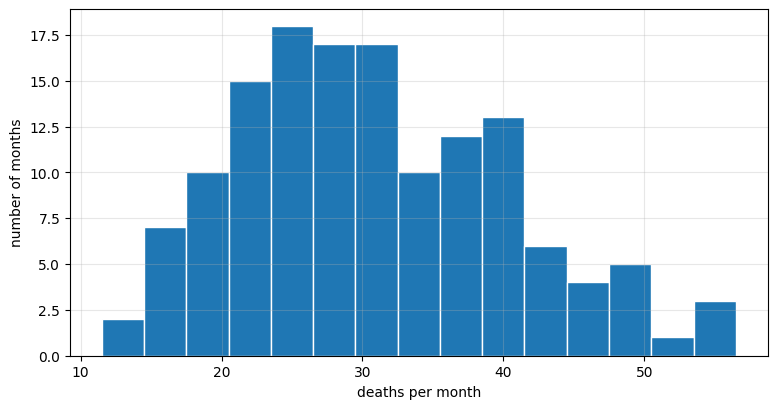

mean                  30.91
median                30.00
variance (ddof=1)     92.25
std. dev. (ddof=1)     9.60
min                   13.00
max                   56.00
highest months: {'2024-12': 56, '2023-12': 54, '2025-12': 54, '2018-12': 51}
lowest months:  {'2020-06': 13, '2019-11': 14}


In [3]:
bins = np.arange(11.5, 59.5, 3)  # width-3 bins centred on integers
fig, ax = plt.subplots()
ax.hist(y, bins=bins, edgecolor="white")
ax.set_xlabel("deaths per month")
ax.set_ylabel("number of months")
plt.show()

print(pd.Series({"mean": y.mean(), "median": np.median(y), "variance (ddof=1)": y.var(ddof=1),
                 "std. dev. (ddof=1)": y.std(ddof=1), "min": y.min(), "max": y.max()}).round(2).to_string())
fmt = lambda s: s.rename(lambda d: d.strftime("%Y-%m")).to_dict()
print("highest months:", fmt(ys.nlargest(4)))
print("lowest months: ", fmt(ys.nsmallest(2)))

### Answer 1

Mean $= 30.91$, median $= 30$, variance $= 92.25$, s.d. $= 9.60$; range 13 to 56. The histogram is flat and slightly right-skewed, with a second group around 37 to 42; the highest months are all Decembers. The variance is three times the mean.

---
## Question 2: Gaussian model, $y_t \mid \mu,\sigma^2 \sim N(\mu,\sigma^2)$ i.i.d.

### Answer 2(a)

$$\ell(\mu,\sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{t=1}^n (y_t-\mu)^2$$

Setting the scores to zero gives $\hat\mu = \bar y$ and $\hat\sigma^2 = \frac{1}{n}\sum_{t=1}^n (y_t-\bar y)^2$.

In [4]:
mu_hat = y.mean()
sigma2_hat = y.var(ddof=0)   # MLE divides by n
s = y.std(ddof=1)            # unbiased s^2 divides by n-1; used in the t interval
t_q = t.ppf(0.975, n - 1)
ci_mu = (mu_hat - t_q * s / np.sqrt(n), mu_hat + t_q * s / np.sqrt(n))

pd.Series({"mu_hat": mu_hat, "sigma2_hat (MLE, /n)": sigma2_hat, "s^2 (/(n-1))": s**2,
           "95% CI lower": ci_mu[0], "95% CI upper": ci_mu[1]}).round(3).to_frame("Gaussian model")

,Gaussian model
mu_hat,30.914
"sigma2_hat (MLE, /n)",91.593
s^2 (/(n-1)),92.252
95% CI lower,29.309
95% CI upper,32.519


### Answer 2(b)

$\hat\mu = 30.91$, $\hat\sigma^2 = 91.59$; 95% CI for $\mu$: $\bar y \pm t_{0.975,139}\, s/\sqrt n = [29.31,\ 32.52]$.

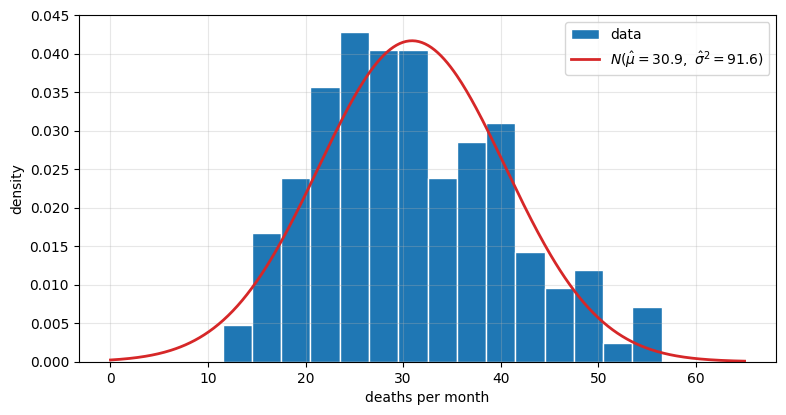

P(Y < 0) under the fitted normal = 6.2e-04


In [5]:
grid = np.linspace(0, 65, 400)
fig, ax = plt.subplots()
ax.hist(y, bins=bins, density=True, edgecolor="white", label="data")
ax.plot(grid, norm.pdf(grid, mu_hat, np.sqrt(sigma2_hat)), lw=2, color="C3",
        label=rf"$N(\hat\mu={mu_hat:.1f},\ \hat\sigma^2={sigma2_hat:.1f})$")
ax.set_xlabel("deaths per month")
ax.set_ylabel("density")
ax.legend()
plt.show()

print(f"P(Y < 0) under the fitted normal = {norm.cdf(0, mu_hat, np.sqrt(sigma2_hat)):.1e}")

### Answer 2(c)

Rough fit: right centre and spread, wrong shape (the data are flatter and skewed). The Gaussian ignores that the data are non-negative integer counts, that their variance grows with the mean, and the time structure (Question 4).

---
## Question 3: Poisson model, $y_t \mid \lambda \sim \text{Poisson}(\lambda)$ independent

### Answer 3(a)

$$\ell(\lambda) = \Big(\sum_t y_t\Big)\log\lambda - n\lambda + \text{const}, \qquad \ell'(\lambda) = 0 \Rightarrow \hat\lambda = \bar y.$$

$I(\lambda) = n/\lambda$, so $\text{se}(\hat\lambda) = \sqrt{\hat\lambda/n}$.

In [6]:
lam_hat = y.mean()
se_lam = np.sqrt(lam_hat / n)
ci_lam = (lam_hat - 1.96 * se_lam, lam_hat + 1.96 * se_lam)

pd.Series({"lambda_hat": lam_hat, "se = sqrt(lambda_hat/n)": se_lam,
           "95% CI lower": ci_lam[0], "95% CI upper": ci_lam[1]}).round(3).to_frame("Poisson model")

,Poisson model
lambda_hat,30.914
se = sqrt(lambda_hat/n),0.470
95% CI lower,29.993
95% CI upper,31.835


### Answer 3(b)

$\hat\lambda = 30.91$, se $= 0.47$, 95% Wald CI $[29.99,\ 31.84]$, about half as wide as the Gaussian one.

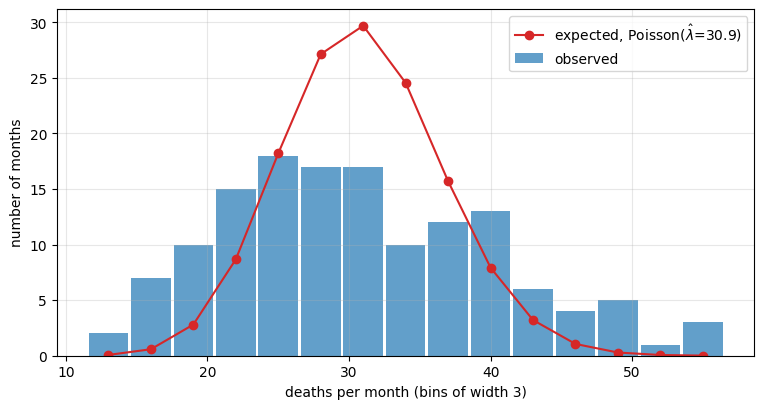

,observed,Poisson
P(y <= 20),0.136,0.025
P(21 <= y <= 41),0.729,0.942
P(y >= 42),0.136,0.033


In [7]:
obs_bin, _ = np.histogram(y, bins=bins)
exp_pois = n * np.diff(poisson.cdf(np.floor(bins), lam_hat))   # expected months per width-3 bin
mids = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots()
ax.bar(mids, obs_bin, width=2.8, color="C0", alpha=0.7, label="observed")
ax.plot(mids, exp_pois, "o-", color="C3", label=rf"expected, Poisson($\hat\lambda$={lam_hat:.1f})")
ax.set_xlabel("deaths per month (bins of width 3)")
ax.set_ylabel("number of months")
ax.legend()
plt.show()

pd.DataFrame({
    "observed": [(y <= 20).mean(), ((y > 20) & (y < 42)).mean(), (y >= 42).mean()],
    "Poisson": [poisson.cdf(20, lam_hat), poisson.cdf(41, lam_hat) - poisson.cdf(20, lam_hat),
                poisson.sf(41, lam_hat)],
}, index=["P(y <= 20)", "P(21 <= y <= 41)", "P(y >= 42)"]).round(3)

### Answer 3(c)

The Poisson is too concentrated: it puts 0.942 of the mass in $[21, 41]$ against 0.729 observed, and only 0.025 and 0.033 in the tails against 0.136 each.

In [8]:
ybar, s2 = y.mean(), y.var(ddof=1)
D = np.sum((y - ybar) ** 2) / ybar   # ~ chi2(n-1) under the Poisson model
pd.Series({"mean": ybar, "variance (ddof=1)": s2, "variance/mean": s2 / ybar,
           "dispersion statistic D": D, "df": n - 1,
           "p-value P(chi2_139 > D)": chi2.sf(D, n - 1)}).to_frame("dispersion check").map(lambda v: f"{v:.4g}")

,dispersion check
mean,30.91
variance (ddof=1),92.25
variance/mean,2.984
dispersion statistic D,414.8
df,139
p-value P(chi2_139 > D),3.087e-29


### Answer 3(d)

Yes, strong overdispersion: variance/mean $= 2.98$, dispersion test $D = 414.8 \sim \chi^2_{139}$, $p \approx 3\times10^{-29}$. The Poisson se in 3(b) is too small.

In [9]:
ll_norm = norm.logpdf(y, mu_hat, np.sqrt(sigma2_hat)).sum()
ll_pois = poisson.logpmf(y, lam_hat).sum()
fit = pd.DataFrame({"k (parameters)": [2, 1], "max log-lik": [ll_norm, ll_pois]},
                   index=["Gaussian", "Poisson"])
fit["AIC"] = -2 * fit["max log-lik"] + 2 * fit["k (parameters)"]
fit.round(2)

,k (parameters),max log-lik,AIC
Gaussian,2,-514.87,1033.73
Poisson,1,-571.51,1145.03


### Answer 3(e)

The Gaussian fits better: AIC $1033.7$ against $1145.0$, because its free variance absorbs the overdispersion. Neither model accounts for the time structure.

---
## Question 4: Time series plot

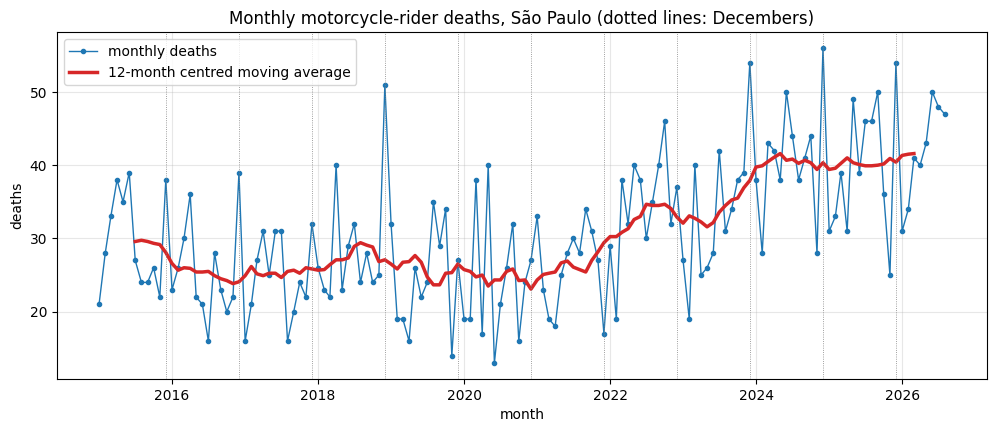

mean by year: {2015: 29.6, 2016: 25.5, 2017: 24.7, 2018: 28.9, 2019: 24.8, 2020: 24.3, 2021: 26.1, 2022: 34.7, 2023: 33.6, 2024: 40.8, 2025: 39.9, 2026: 41.8}
mean by calendar month: {1: 27.2, 2: 24.3, 3: 32.4, 4: 30.5, 5: 32.7, 6: 32.3, 7: 32.6, 8: 31.5, 9: 32.3, 10: 30.8, 11: 25.5, 12: 39.3}
lag-1 autocorrelation = 0.375  (approx. 95% band under i.i.d.: ±0.166)


In [10]:
ma12 = ys.rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(ys.index, ys, "o-", ms=3, lw=1, label="monthly deaths")
ax.plot(ma12.index, ma12, lw=2.5, color="C3", label="12-month centred moving average")
for d in ys[ys.index.month == 12].index:
    ax.axvline(d, color="grey", lw=0.6, ls=":")
ax.set_xlabel("month")
ax.set_ylabel("deaths")
ax.set_title("Monthly motorcycle-rider deaths, São Paulo (dotted lines: Decembers)")
ax.legend(loc="upper left")
plt.show()

print("mean by year:", ys.groupby(ys.index.year).mean().round(1).to_dict())
print("mean by calendar month:", ys.groupby(ys.index.month).mean().round(1).to_dict())
r1 = np.corrcoef(y[:-1], y[1:])[0, 1]
print(f"lag-1 autocorrelation = {r1:.3f}  (approx. 95% band under i.i.d.: ±{1.96/np.sqrt(n):.3f})")

### Answer 4

Not i.i.d. The level is flat at about 25 to 30 until 2021, jumps in 2022 and reaches about 40 from 2024 on. Decembers peak (mean 39.3), and the lag-1 autocorrelation is 0.375 (band $\pm 0.166$). Pooling the two regimes explains the overdispersion in 3(d).

---
## Question 5: Structural break at $\tau$

In [11]:
tau = 84   # Part 1 = Jan 2015 to Dec 2021 (84 months), Part 2 = Jan 2022 to Aug 2026
y1, y2 = y[:tau], y[tau:]
n1, n2 = len(y1), len(y2)
print(f"tau = {tau}: last month of Part 1 = {dates[tau-1]:%Y-%m}, first month of Part 2 = {dates[tau]:%Y-%m}")
print(f"n1 = {n1}, n2 = {n2}")

tau = 84: last month of Part 1 = 2021-12, first month of Part 2 = 2022-01
n1 = 84, n2 = 56


### Choice of $\tau$

$\tau = 84$ (Dec 2021): every annual mean is below 30 up to 2021 and above 33 from 2022 on, and Part 1 has seven full years.

In [12]:
def normal_mle(x):
    """MLE of (mu, sigma^2) for an i.i.d. normal sample (variance with ddof=0)."""
    return x.mean(), x.var(ddof=0)


def ll_normal(x):
    """Maximised normal log-likelihood of sample x."""
    m, v = normal_mle(x)
    return norm.logpdf(x, m, np.sqrt(v)).sum()


def ll_poisson(x, lam=None):
    """Poisson log-likelihood of sample x at lam (default: the MLE, the sample mean)."""
    return poisson.logpmf(x, x.mean() if lam is None else lam).sum()


mu1, s2_1 = normal_mle(y1)
mu2, s2_2 = normal_mle(y2)
lam1, lam2 = y1.mean(), y2.mean()

pd.DataFrame({"Part 1 (2015-01 to 2021-12)": [n1, mu1, s2_1, lam1],
              "Part 2 (2022-01 to 2026-08)": [n2, mu2, s2_2, lam2],
              "No break (items 2-3)": [n, mu_hat, sigma2_hat, lam_hat]},
             index=["n", "mu_hat", "sigma2_hat (MLE)", "lambda_hat"]).round(3)

,Part 1 (2015-01 to 2021-12),Part 2 (2022-01 to 2026-08),No break (items 2-3)
n,84.000,56.000,140.000
mu_hat,26.262,37.893,30.914
sigma2_hat (MLE),50.193,72.524,91.593
lambda_hat,26.262,37.893,30.914


### Answer 5(a) and 5(b)

Part 1: $\hat\mu_1 = \hat\lambda_1 = 26.26$, $\hat\sigma_1^2 = 50.19$. Part 2: $\hat\mu_2 = \hat\lambda_2 = 37.89$, $\hat\sigma_2^2 = 72.52$.

In [13]:
def ci_t(x):
    """95% t interval for the mean of x."""
    h = t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h


def ci_wald_pois(x):
    """95% Wald interval for a Poisson rate, se = sqrt(lambda_hat / n)."""
    h = 1.96 * np.sqrt(x.mean() / len(x))
    return x.mean() - h, x.mean() + h


ci = pd.DataFrame([ci_t(y1), ci_t(y2), ci_wald_pois(y1), ci_wald_pois(y2)],
                  index=["mu1", "mu2", "lambda1", "lambda2"], columns=["95% lower", "95% upper"])
ci.insert(0, "estimate", [mu1, mu2, lam1, lam2])
display(ci.round(2))

# H0: no break (models of Q2 and Q3) vs H1: separate parameters in each part
LR_pois = 2 * (ll_poisson(y1) + ll_poisson(y2) - ll_poisson(y))   # df = 1
LR_norm = 2 * (ll_normal(y1) + ll_normal(y2) - ll_normal(y))      # df = 2 (mean and variance)
pd.DataFrame({"LR": [LR_pois, LR_norm], "df": [1, 2],
              "p-value": [f"{chi2.sf(LR_pois, 1):.1e}", f"{chi2.sf(LR_norm, 2):.1e}"]},
             index=["Poisson: lambda1 = lambda2", "Normal: mu1 = mu2, sigma1^2 = sigma2^2"]).round(2)

,estimate,95% lower,95% upper
mu1,26.26,24.72,27.81
mu2,37.89,35.59,40.19
lambda1,26.26,25.17,27.36
lambda2,37.89,36.28,39.51


,LR,df,p-value
Poisson: lambda1 = lambda2,144.25,1,3.1e-33
"Normal: mu1 = mu2, sigma1^2 = sigma2^2",63.60,2,1.6e-14


### Answer 5(c)

The CIs of the two parts do not overlap. Both LR tests reject the no-break model: Poisson $LR = 144.25$ (df 1, $p = 3\times10^{-33}$), Normal $LR = 63.60$ (df 2, $p = 2\times10^{-14}$).

,last month of Part 1,lambda1,lambda2,LR Poisson,p Poisson,LR Normal (df=2),p Normal
tau,,,,,,,
60,2019-12,26.68,34.09,61.66,4.1e-15,30.13,2.9e-07
72,2020-12,26.29,35.81,102.57,4.2e-24,43.54,3.5e-10
84,2021-12,26.26,37.89,144.25,3.1e-33,63.60,1.6e-14
86,2022-02,26.21,38.41,155.96,8.6e-36,69.52,8.0e-16
96,2022-12,27.31,38.77,123.22,1.2e-28,53.11,2.9e-12
108,2023-12,28.01,40.72,120.84,4.1e-28,52.19,4.7e-12


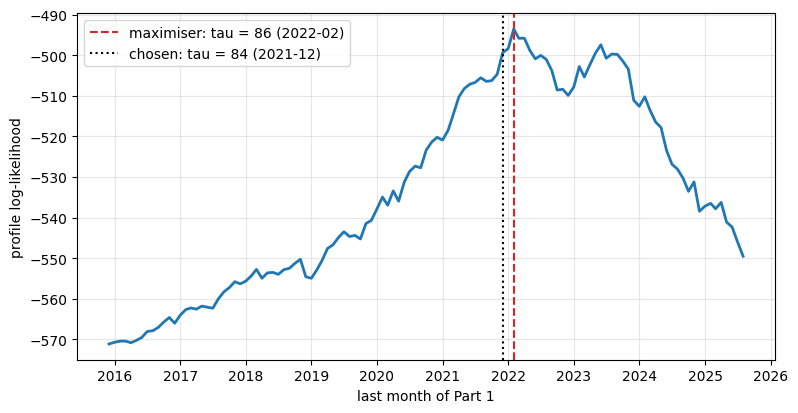

tau* = 86 (2022-02), max log-lik = -493.53, log-lik at tau = 84: -499.39


In [14]:
def break_analysis(tau):
    """Items 5(a)-(c) for a given tau; returns one row of the sensitivity table."""
    a, b = y[:tau], y[tau:]
    lr_p = 2 * (ll_poisson(a) + ll_poisson(b) - ll_poisson(y))
    lr_n = 2 * (ll_normal(a) + ll_normal(b) - ll_normal(y))
    return {"tau": tau, "last month of Part 1": f"{dates[tau-1]:%Y-%m}",
            "lambda1": round(a.mean(), 2), "lambda2": round(b.mean(), 2),
            "LR Poisson": round(lr_p, 2), "p Poisson": f"{chi2.sf(lr_p, 1):.1e}",
            "LR Normal (df=2)": round(lr_n, 2), "p Normal": f"{chi2.sf(lr_n, 2):.1e}"}


display(pd.DataFrame([break_analysis(tt) for tt in [60, 72, 84, 86, 96, 108]]).set_index("tau"))

# profile log-likelihood of the Poisson break model, at least 12 months in each part
taus = np.arange(12, n - 11)
prof = np.array([ll_poisson(y[:tt]) + ll_poisson(y[tt:]) for tt in taus])
tau_star = taus[prof.argmax()]

fig, ax = plt.subplots()
ax.plot(dates[taus - 1], prof, lw=2)
ax.axvline(dates[tau_star - 1], color="C3", ls="--", label=f"maximiser: tau = {tau_star} ({dates[tau_star-1]:%Y-%m})")
ax.axvline(dates[tau - 1], color="k", ls=":", label=f"chosen: tau = {tau} ({dates[tau-1]:%Y-%m})")
ax.set_xlabel("last month of Part 1")
ax.set_ylabel("profile log-likelihood")
ax.legend()
plt.show()
print(f"tau* = {tau_star} ({dates[tau_star-1]:%Y-%m}), max log-lik = {prof.max():.2f}, "
      f"log-lik at tau = {tau}: {prof[taus == tau][0]:.2f}")

### Answer 5(d)

Confirmed: every $\tau$ tried rejects the no-break model ($p < 10^{-5}$). The profile likelihood peaks at $\tau = 86$ (Feb 2022), close to our choice. $\hat\lambda_2$ grows with $\tau$, so the level keeps rising after the break.

In [15]:
def dispersion_row(x):
    """Mean, variance, variance/mean and the chi2(n-1) dispersion test for a count sample."""
    m, v = x.mean(), x.var(ddof=1)
    D = np.sum((x - m) ** 2) / m
    return {"n": len(x), "mean": m, "variance": v, "variance/mean": v / m, "p-value": chi2.sf(D, len(x) - 1)}


disp = pd.DataFrame({"full sample": dispersion_row(y), "Part 1": dispersion_row(y1), "Part 2": dispersion_row(y2)}).T
display(disp.assign(n=disp["n"].astype(int), **{"p-value": disp["p-value"].map("{:.1e}".format)}).round(2))

not_dec = dates.month != 12   # how much of the dispersion is the December peak
print("variance/mean without Decembers: Part 1 = {:.2f}, Part 2 = {:.2f}".format(
    y1[not_dec[:tau]].var(ddof=1) / y1[not_dec[:tau]].mean(),
    y2[not_dec[tau:]].var(ddof=1) / y2[not_dec[tau:]].mean()))

,n,mean,variance,variance/mean,p-value
full sample,140,30.91,92.25,2.98,3.1e-29
Part 1,84,26.26,50.80,1.93,7.1e-07
Part 2,56,37.89,73.84,1.95,3.2e-05


variance/mean without Decembers: Part 1 = 1.62, Part 2 = 1.68


### Answer 5(e)

Variance/mean falls from 2.98 to 1.93 (Part 1) and 1.95 (Part 2) but stays significantly above 1. What remains comes mostly from the December peak and the trend in Part 2.